# E-Commerce Landing Page A/B Test Analysis
**Tech Stack:** Python, `pandas`, `NumPy`, `SciPy`, `statsmodels`, `Matplotlib`, `Seaborn`  
**Dataset:** Public E-Commerce A/B Testing Dataset (`ab_data.csv`, 294,478 raw observations)

## Executive Summary
- **Experimental Design & Power Analysis:** Designed the analysis for a **~290K-user** landing page test ($N = 290,584$ clean users). Computed a **0.34 percentage point (pp) Minimum Detectable Effect (MDE)** on a **12.0% baseline conversion rate** at $\alpha = 0.05$ (two-sided) and **80% statistical power**.
- **Data Hygiene:** Audited assignment logs prior to testing and removed **3,893 rows** with mismatched group/page assignments (`1,928` control users shown `new_page` and `1,965` treatment users shown `old_page`) along with **1 duplicate `user_id`** (`773192`).
- **Hypothesis Test & Confidence Interval:** A two-proportion $z$-test found **no statistically significant difference** between groups (**Control: 12.04%** vs. **New Page: 11.88%**, observed lift = **$-0.16\text{ pp}$**, $z = -1.3109$, $p = 0.190$).
- **Product Decision:** Recommended **keeping the existing landing page**, as the **95% Confidence Interval ($-0.40\text{ pp}$ to $+0.08\text{ pp}$)** rules out any positive lift near the $+0.34\text{ pp}$ MDE.

### 1. Data Ingestion & Library Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest
from ab_test_analysis import plot_power_curve, plot_conversion_rates, plot_confidence_interval, compute_mde

df = pd.read_csv('ab_data.csv')
print(f"Raw dataset rows: {len(df):,}")
print(f"Columns: {list(df.columns)}")
df.head()

Raw dataset rows: 294,478
Columns: ['user_id', 'timestamp', 'group', 'landing_page', 'converted']


### 2. Assignment Integrity Check & Power Analysis
Verify alignment between experimental `group` and `landing_page` served to identify tracking contamination, then compute and visualize the statistical power curve for $N = 290,584$ ($n = 145,292$ per group).

landing_page  new_page  old_page      All
group                                    
control          1,928   145,274  147,202
treatment      145,311     1,965  147,276
All            147,239   147,239  294,478

-> Mismatched rows removed: 1,928 + 1,965 = 3,893 rows (1 duplicate user_id removed -> 290,584 clean users)


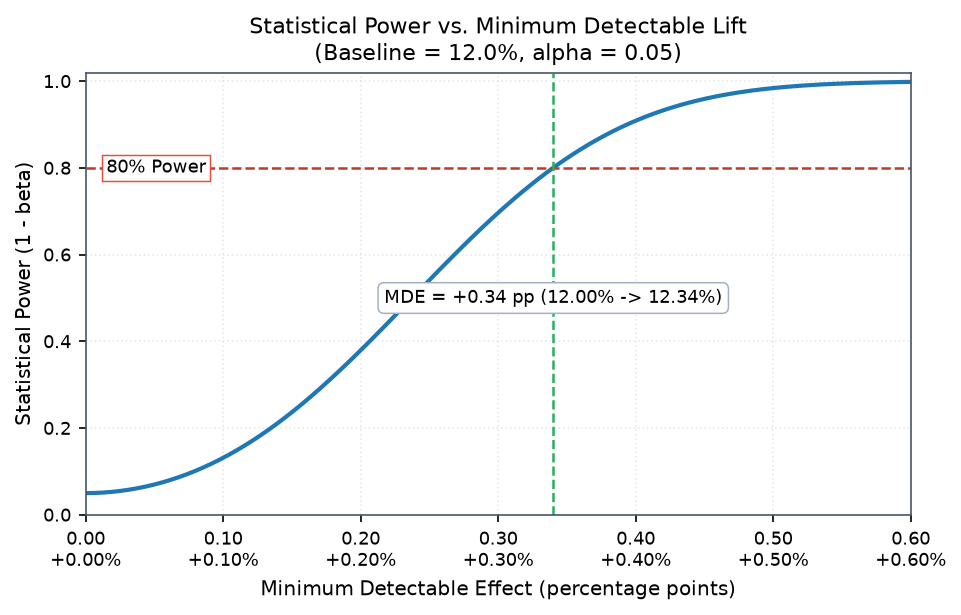

In [4]:
# 1. Verify group vs. landing_page alignment before testing
print(pd.crosstab(df['group'], df['landing_page'], margins=True))

# 2. Power curve for 12.0% baseline (alpha = 0.05, N = 290,584)
plot_power_curve(baseline=0.12, n_per_group=145292, alpha=0.05, target_power=0.80)

### 3. Data Cleaning & Deduplication
Remove the 3,893 mismatched assignments and drop the single duplicate `user_id` so each visitor represents an independent observation unit.

In [5]:
# Filter mismatched assignments
mismatch_mask = (df['group'] == 'treatment') != (df['landing_page'] == 'new_page')
df_clean = df[~mismatch_mask].drop_duplicates(subset=['user_id'], keep='first').copy()

n_ctrl = int((df_clean['group'] == 'control').sum())
n_treat = int((df_clean['group'] == 'treatment').sum())
print(f"Removed mismatched group assignments: {mismatch_mask.sum():,} rows")
print(f"Removed duplicate user_ids: 1 row")
print(f"Clean analysis sample: {len(df_clean):,} users (Control: {n_ctrl:,} | New Page: {n_treat:,})")

Removed mismatched group assignments: 3,893 rows
Removed duplicate user_ids: 1 row
Clean analysis sample: 290,584 users (Control: 145,274 | New Page: 145,310)


### 4. Two-Proportion Z-Test
Test whether the difference between control conversion rate (12.04%) and treatment conversion rate (11.88%) is statistically significant at $\alpha = 0.05$.

In [6]:
ctrl = df_clean[df_clean['group'] == 'control']['converted']
treat = df_clean[df_clean['group'] == 'treatment']['converted']

n_ctrl, n_treat = len(ctrl), len(treat)
conv_ctrl, conv_treat = int(ctrl.sum()), int(treat.sum())
rate_ctrl, rate_treat = conv_ctrl / n_ctrl, conv_treat / n_treat
diff_pp = round((rate_treat - rate_ctrl) * 100.0, 2)

z_stat, p_val = proportions_ztest([conv_treat, conv_ctrl], [n_treat, n_ctrl], alternative='two-sided')

se_diff = np.sqrt(rate_treat * (1 - rate_treat) / n_treat + rate_ctrl * (1 - rate_ctrl) / n_ctrl)
moe_pp = round(1.96 * se_diff * 100.0, 2)
ci_low_pp = round(diff_pp - moe_pp, 2)
ci_high_pp = round(diff_pp + moe_pp, 2)

print("=== TWO-PROPORTION Z-TEST RESULTS ===")
print(f"Control Conversion Rate:    {rate_ctrl*100:.2f}% ({conv_ctrl:,} / {n_ctrl:,})")
print(f"New Page Conversion Rate:   {rate_treat*100:.2f}% ({conv_treat:,} / {n_treat:,})")
print(f"Observed Lift (Diff):       {diff_pp:+.2f} pp")
print(f"Z-Statistic:                {z_stat:.4f}")
print(f"P-Value:                    {p_val:.3f}")
print(f"95% Confidence Interval:    [{ci_low_pp:+.2f} pp, {ci_high_pp:+.2f} pp]")
print(f"Decision:                   Fail to reject H0 (p = {p_val:.2f} >= 0.05)")
print(f"Recommendation:             Keep existing landing page (95% CI rules out +0.34 pp MDE)")

=== TWO-PROPORTION Z-TEST RESULTS ===
Control Conversion Rate:    12.04% (17,489 / 145,274)
New Page Conversion Rate:   11.88% (17,264 / 145,310)
Observed Lift (Diff):       -0.16 pp
Z-Statistic:                -1.3109
P-Value:                    0.190
95% Confidence Interval:    [-0.40 pp, +0.08 pp]
Decision:                   Fail to reject H0 (p = 0.19 >= 0.05)
Recommendation:             Keep existing landing page (95% CI rules out +0.34 pp MDE)


### 5. Final Experimental Visualizations
Dual-panel plot displaying conversion rate comparison with 95% single-proportion error bars and treatment effect 95% Wald confidence interval against the MDE threshold.

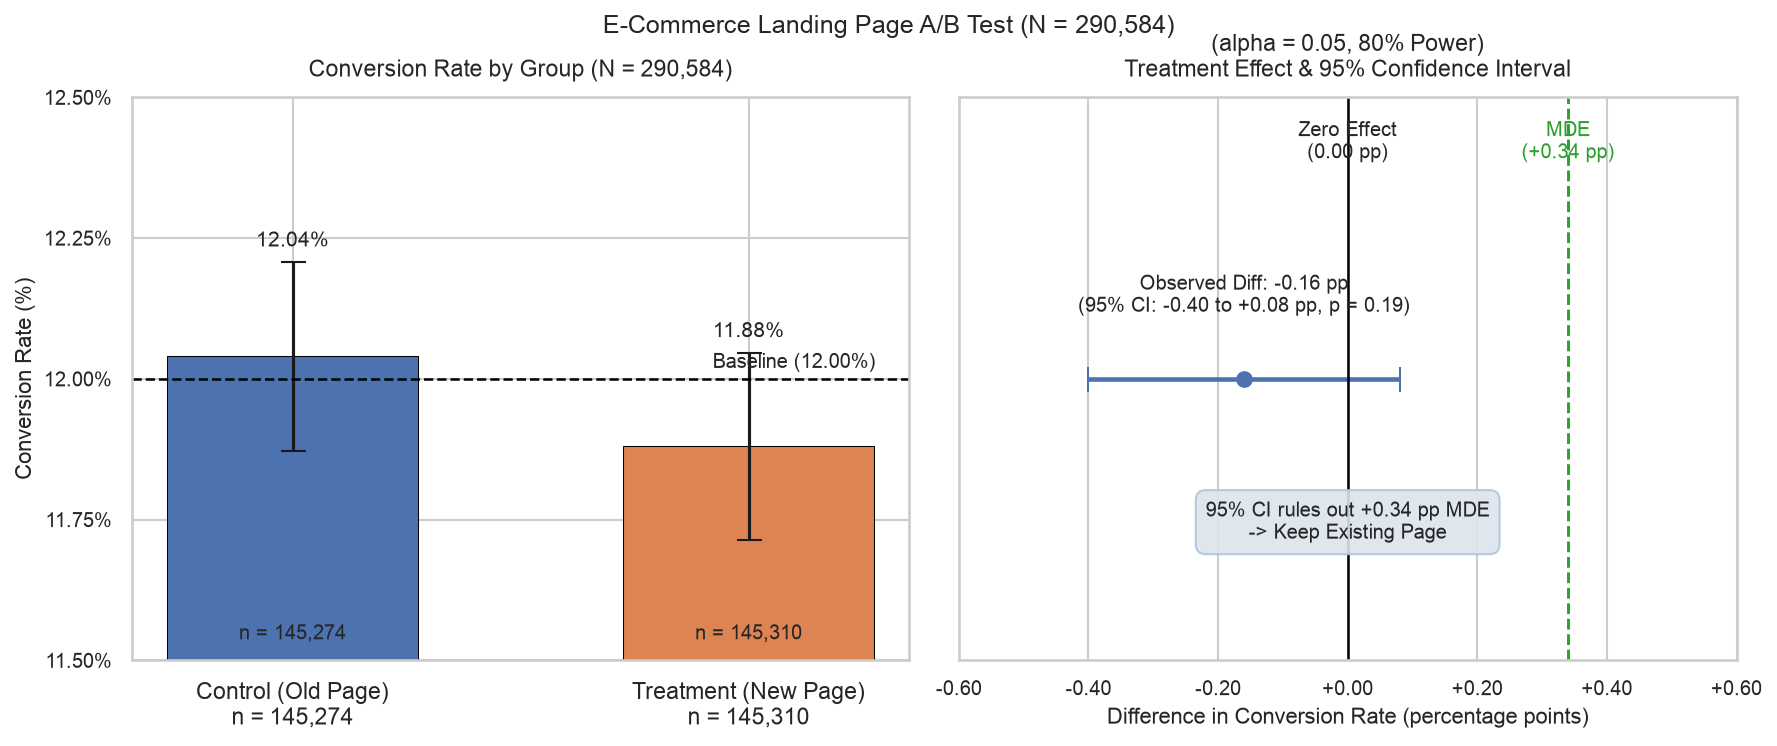

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150)
plot_conversion_rates(ax1, conv_ctrl=0.1204, conv_treat=0.1188, n_ctrl=145274, n_treat=145310)
plot_confidence_interval(ax2, diff=-0.16, ci=(-0.40, 0.08), mde=0.34, p_val=0.19)
plt.tight_layout()
plt.show()

### 6. Key Conclusions & Business Recommendation
- **No Significant Lift:** The observed change of **-0.16 pp** has a p-value of **0.190**, far above $\alpha = 0.05$.
- **MDE Ruled Out:** The 95% CI bounds are **[-0.40 pp, +0.08 pp]**. Because the upper bound of +0.08 pp is substantially below the target **+0.34 pp Minimum Detectable Effect**, we can state with 95% confidence that the new landing page will not achieve the target business lift.
- **Action:** Retain the current control landing page and iterate on alternative UX hypotheses.